# [Text-To-Image Synthesis](https://happy-jihye.github.io/gan/gan-4/)

## Network Architecture

- Generator: $\mathbb{R}^Z$ x $\mathbb{R}^T$ -> $\mathbb{R}^D$
- Discriminator: $\mathbb{R}^D$ x $\mathbb{R}^T$ -> $0,1$
  - T: dim of text description embedding
  - D: dim of text image embedding
  - Z: dim of noise $(z \in \mathbb{R}^Z \sim N(0,1))$

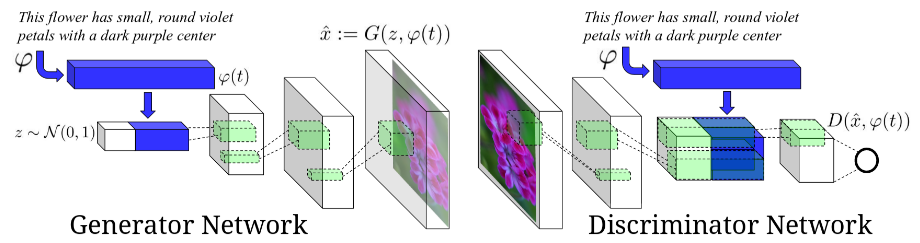

### DCGAN
- DCGAN은 GAN에 Convolutional NN Layer를 적용하여 training을 안정화했고, GAN의 Generator와 Discriminator의 내부 네트워크를 이해할 수 있게 했다.
- Convolutional RNN으로 encoding한 text features와 DCGAN을 활용해서 이미지를 합성한다.

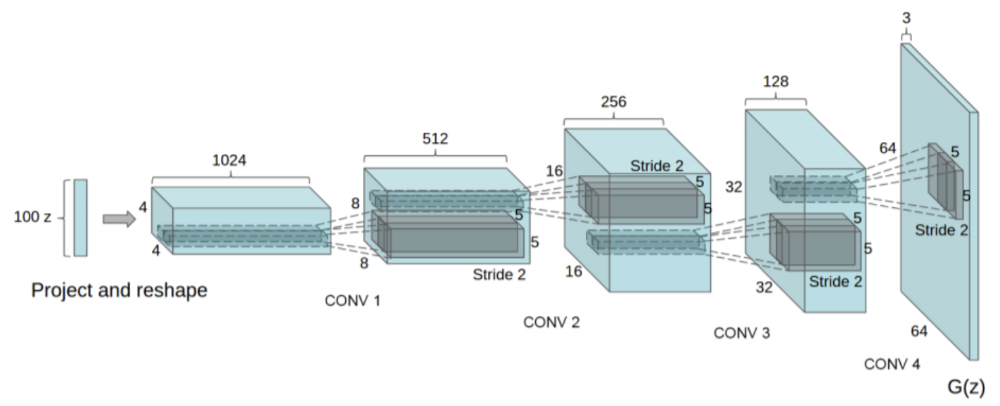

### Generator
1. `text encoder φ`를 사용해서 `text query t`를 encoding 한다.
2. encoding의 결과값`(φ(t))`을 FC layer에 넣어 compress한 후 Leaky-ReLU를 사용해서 128-dim의 작은 차원으로 compression한다.
3. 이 값을 `noise vector z`와 concate한후 deconvolutional network를 통해 generate image를 얻는다.

### Discriminator
1. stride-2 convolution layer와 BN기법, leaky ReLU function을 이용해서 학습을 한다.
2. 1번의 과정을 4x4 conv layer가 될때까지 반복한다. (여러개의 layer를 쌓음)
3. 4x4 conv layer가 되면 compressiong된 `embedding vector φ`를 여러개 복사해서 conv layer 뒤에 이어붙인다.(depth concatenation)
4. 1x1 conv layer가 되도록 연산을 한 후 final score를 얻는다.
5. 이때 모든 conv layer에 대해서 BN을 해준다.

## Matching-aware discriminator (GAN-CLS)
- conditional GAN은 discriminator가 (text, images) pair가 진짜인지 가짜인지 판단하도록 학습한다. 이때 문제점은 discriminator는 real training image가 어떤 text embedding context와 match되는지 모른다는 점이다.
- 즉, real image가 자기를 설명하지 않은 text와 match될 수도 있다.(mismatch)
- 따라서 (real image, mismatched text term)을 추가하도록 GAN training algorithm을 수정하여 discriminator가 fake에 대해서도 학습을 할 수 있게 한다.

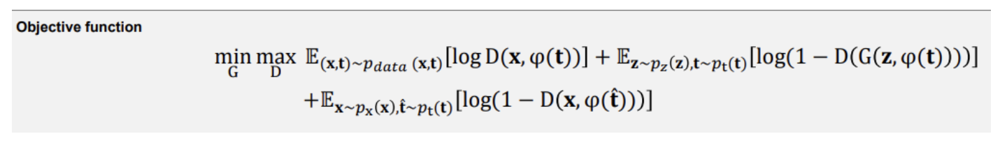

## Learning with manifold interpolation (GAN-INT)
- 우리가 네트워크를 학습시킬 때에는 주어진 text만을 가지고 image를 만들지만, 실제로 이를 사용할 때에는 training dataset에 없는 text를 줘도 image를 생성할 수 있어야한다.
- 즉, training dataset에 있는 text와 비슷한 text를 입력했을 때에도 image를 생성해야하기 때문에 interpolation의 방식을 사용하면 조금 더 효과적으로 학습을 할 수 있게 된다.

## Inverting the generator for style transferPermalink
- `text encoding φ(t)`는 image content(ex. flower shape, colors)를 찾아내는 역할을 한다. (text에서 이미지로 표현할 만한 feature들을 추출) 이미지를 생성하려면 사물의 특징들을 잘 추출하여 생성하는 것도 중요하지만, 그 외의 정보들(ex.배경이나 자세)들을 생성하는 것도 중요하다.

## Qualitative Results

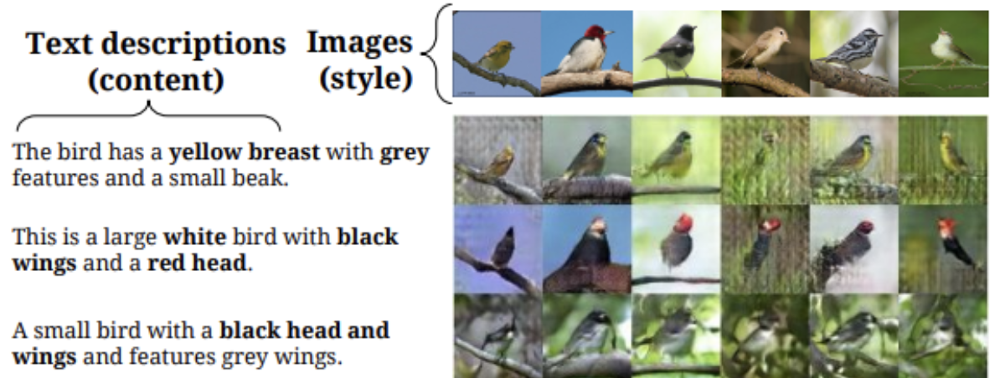

# [DCGAN - 예제](https://github.com/yashashwita20/text-to-image-using-GAN/blob/main/DCGAN_Text2Image.ipynb)

## Setup

In [ ]:
# %pip install imageio==2.37.0 h5py==3.14.0 torch==2.8.0 torchvision==0.23.0

Note: you may need to restart the kernel to use updated packages.


In [2]:
import torch
import torch.nn as nn
import torchvision.utils as vutils
from torch.autograd import Variable
from torch.utils.data import Dataset, DataLoader

import os
import io
import time
import imageio
import numpy as np
from datetime import datetime

from PIL import Image
import matplotlib.pyplot as plt

import h5py

import warnings
warnings.filterwarnings("ignore")

In [3]:
# Setting device to cuda
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using Device", device)

Using Device cuda


In [4]:
# saving current date and time
date = datetime.now().strftime('%Y%m%d')
start_time = time.time()

In [5]:
# directory to store output images
output_save_path = './generated_images/'
os.makedirs(output_save_path, exist_ok=True)

In [6]:
# directory to store trained models
model_save_path = './saved_models/'
os.makedirs(model_save_path, exist_ok=True)

In [7]:
# setting up parameters
noise_dim = 100
embed_dim = 1024
embed_out_dim = 128
batch_size = 256 #128
real_label = 1.
fake_label = 0.
learning_rate = 0.0002
l1_coef = 50
l2_coef = 100

num_epochs = 100 #250
log_interval = 50 #43

## [Download Dataset](https://www.kaggle.com/datasets/kmahesh541/flowershd5dataset/data)

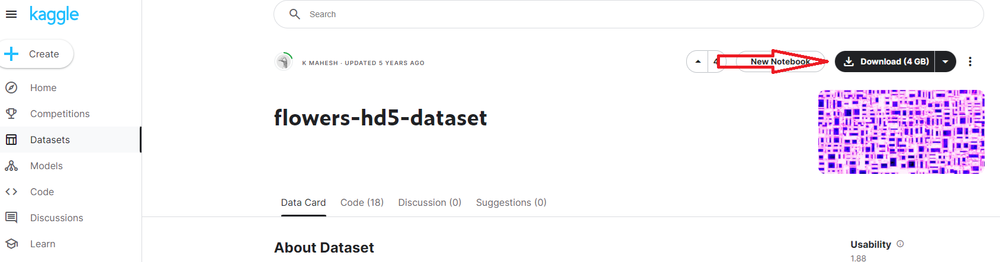

In [ ]:
# !pip install kagglehub==1.0.1

In [9]:
import kagglehub

# Download latest version
dataset_root = kagglehub.dataset_download("kmahesh541/flowershd5dataset")

print("Path to dataset files:", dataset_root)

Path to dataset files: /root/.cache/kagglehub/datasets/kmahesh541/flowershd5dataset/versions/1


In [10]:
import os

# 폴더 안을 더 탐색
for root, dirs, files in os.walk(dataset_root):
    for f in files:
        print(os.path.join(root, f))

/root/.cache/kagglehub/datasets/kmahesh541/flowershd5dataset/versions/1/data/flowers/flowers.hdf5
/root/.cache/kagglehub/datasets/kmahesh541/flowershd5dataset/versions/1/flowers-hd5/data/flowers/flowers.hdf5


## Dataset

In [11]:
class Text2ImageDataset(Dataset):

    def __init__(self, datasetFile, transform=None, split=0):
        self.datasetFile = datasetFile
        self.transform = transform
        self.dataset = None
        self.dataset_keys = None
        self.split = 'train' if split == 0 else 'valid' if split == 1 else 'test'
        self.h5py2int = lambda x: int(np.array(x))

    def __len__(self):
        f = h5py.File(self.datasetFile, 'r')
        self.dataset_keys = [str(k) for k in f[self.split].keys()]
        length = len(f[self.split])
        f.close()

        return length

    def __getitem__(self, idx):
        if self.dataset is None:
            self.dataset = h5py.File(self.datasetFile, mode='r')
            self.dataset_keys = [str(k) for k in self.dataset[self.split].keys()]

        example_name = self.dataset_keys[idx]
        example = self.dataset[self.split][example_name]

        # pdb.set_trace()

        right_image = bytes(np.array(example['img']))
        right_embed = np.array(example['embeddings'], dtype=float)
        wrong_image = bytes(np.array(self.find_wrong_image(example['class'])))
        inter_embed = np.array(self.find_inter_embed())

        right_image = Image.open(io.BytesIO(right_image)).resize((64, 64))
        wrong_image = Image.open(io.BytesIO(wrong_image)).resize((64, 64))

        right_image = self.validate_image(right_image)
        wrong_image = self.validate_image(wrong_image)

        try:
            txt = np.array(example['txt']).astype(str)
        except:

            txt = np.array([example['txt'][()].decode('utf-8', errors='replace')])
            txt = np.char.replace(txt, '�', ' ').astype(str)

        sample = {
                'right_images': torch.FloatTensor(right_image),
                'right_embed': torch.FloatTensor(right_embed),
                'wrong_images': torch.FloatTensor(wrong_image),
                'inter_embed': torch.FloatTensor(inter_embed),
                'txt': str(txt)
                 }

        sample['right_images'] = sample['right_images'].sub_(127.5).div_(127.5)
        sample['wrong_images'] =sample['wrong_images'].sub_(127.5).div_(127.5)

        return sample

    def find_wrong_image(self, category):
        idx = np.random.randint(len(self.dataset_keys))
        example_name = self.dataset_keys[idx]
        example = self.dataset[self.split][example_name]
        _category = example['class']

        if _category != category:
            return example['img']

        return self.find_wrong_image(category)

    def find_inter_embed(self):
        idx = np.random.randint(len(self.dataset_keys))
        example_name = self.dataset_keys[idx]
        example = self.dataset[self.split][example_name]
        return example['embeddings']


    def validate_image(self, img):
        img = np.array(img, dtype=float)
        if len(img.shape) < 3:
            rgb = np.empty((64, 64, 3), dtype=np.float32)
            rgb[:, :, 0] = img
            rgb[:, :, 1] = img
            rgb[:, :, 2] = img
            img = rgb

        return img.transpose(2, 0, 1)

In [12]:
# loading dataset
train_dataset = Text2ImageDataset(dataset_root+"/data/flowers/flowers.hdf5",split=0) # split { 0: train, 1: validation, 2: test }
train_loader = DataLoader(train_dataset, batch_size=batch_size,shuffle=True,num_workers=8)
print("Number of batches: ",len(train_loader))

Number of batches:  115


In [13]:
def show_image(inp, title=None):
    """Imshow for Tensor."""
    inp = inp.numpy().transpose((1, 2, 0))
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)  # pause a bit so that plots are updated

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


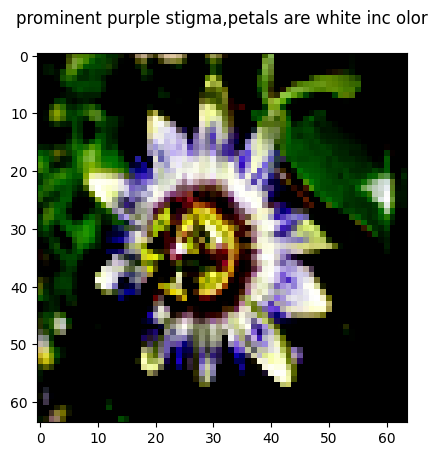

In [14]:
show_image(train_dataset[0]['right_images'], train_dataset[0]['txt'])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


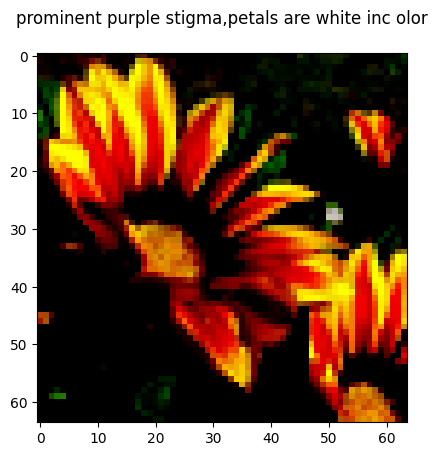

In [15]:
show_image(train_dataset[0]['wrong_images'], train_dataset[0]['txt'])

## Loss function

In [16]:
# loss functions
criterion = nn.BCELoss()
l2_loss = nn.MSELoss()
l1_loss = nn.L1Loss()

## Model

In [17]:
# The Generator model
class Generator(nn.Module):
    def __init__(self, channels, noise_dim=100, embed_dim=1024, embed_out_dim=128):
        super(Generator, self).__init__()
        self.channels = channels
        self.noise_dim = noise_dim
        self.embed_dim = embed_dim
        self.embed_out_dim = embed_out_dim

        # Text embedding layers
        self.text_embedding = nn.Sequential(
            nn.Linear(self.embed_dim, self.embed_out_dim),
            nn.BatchNorm1d(self.embed_out_dim),
            nn.LeakyReLU(0.2, inplace=True)
        )

        # Generator architecture
        model = []
        model += self._create_layer(self.noise_dim + self.embed_out_dim, 512, 4, stride=1, padding=0)
        model += self._create_layer(512, 256, 4, stride=2, padding=1)
        model += self._create_layer(256, 128, 4, stride=2, padding=1)
        model += self._create_layer(128, 64, 4, stride=2, padding=1)
        model += self._create_layer(64, self.channels, 4, stride=2, padding=1, output=True)

        self.model = nn.Sequential(*model)

    def _create_layer(self, size_in, size_out, kernel_size=4, stride=2, padding=1, output=False):
        layers = [nn.ConvTranspose2d(size_in, size_out, kernel_size, stride=stride, padding=padding, bias=False)]
        if output:
            layers.append(nn.Tanh())  # Tanh activation for the output layer
        else:
            layers += [nn.BatchNorm2d(size_out), nn.ReLU(True)]  # Batch normalization and ReLU for other layers
        return layers

    def forward(self, noise, text):
        # Apply text embedding to the input text
        text = self.text_embedding(text)
        text = text.view(text.shape[0], text.shape[1], 1, 1)  # Reshape to match the generator input size
        z = torch.cat([text, noise], 1)  # Concatenate text embedding with noise
        return self.model(z)

In [18]:
# The Embedding model
class Embedding(nn.Module):
    def __init__(self, size_in, size_out):
        super(Embedding, self).__init__()
        self.text_embedding = nn.Sequential(
            nn.Linear(size_in, size_out),
            nn.BatchNorm1d(size_out),
            nn.LeakyReLU(0.2, inplace=True)
        )

    def forward(self, x, text):
        embed_out = self.text_embedding(text)
        embed_out_resize = embed_out.repeat(4, 4, 1, 1).permute(2, 3, 0, 1)  # Resize to match the discriminator input size
        out = torch.cat([x, embed_out_resize], 1)  # Concatenate text embedding with the input feature map
        return out

In [19]:
# The Discriminator model
class Discriminator(nn.Module):
    def __init__(self, channels, embed_dim=1024, embed_out_dim=128):
        super(Discriminator, self).__init__()
        self.channels = channels
        self.embed_dim = embed_dim
        self.embed_out_dim = embed_out_dim

        # Discriminator architecture
        self.model = nn.Sequential(
            *self._create_layer(self.channels, 64, 4, 2, 1, normalize=False),
            *self._create_layer(64, 128, 4, 2, 1),
            *self._create_layer(128, 256, 4, 2, 1),
            *self._create_layer(256, 512, 4, 2, 1)
        )
        self.text_embedding = Embedding(self.embed_dim, self.embed_out_dim)  # Text embedding module
        self.output = nn.Sequential(
            nn.Conv2d(512 + self.embed_out_dim, 1, 4, 1, 0, bias=False), nn.Sigmoid()
        )

    def _create_layer(self, size_in, size_out, kernel_size=4, stride=2, padding=1, normalize=True):
        layers = [nn.Conv2d(size_in, size_out, kernel_size=kernel_size, stride=stride, padding=padding)]
        if normalize:
            layers.append(nn.BatchNorm2d(size_out))
        layers.append(nn.LeakyReLU(0.2, inplace=True))
        return layers

    def forward(self, x, text):
        x_out = self.model(x)  # Extract features from the input using the discriminator architecture
        out = self.text_embedding(x_out, text)  # Apply text embedding and concatenate with the input features
        out = self.output(out)  # Final discriminator output
        return out.squeeze(), x_out

In [20]:
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        m.weight.data.normal_(0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        m.weight.data.normal_(1.0, 0.02)
        m.bias.data.fill_(0)

In [21]:
def process_caption(caption, max_caption_length=200, alphabet="abcdefghijklmnopqrstuvwxyz0123456789-,;.!?:'\"/\\|_@#$%^&*~`+-=<>()[]{} "):
    """
    Converts a caption string to a tensor of one-hot encoded vectors based on the given alphabet.

    Args:
        caption (str): The input caption to be converted to one-hot encoded vectors.
        max_caption_length (int): The maximum length of the output label sequence. If the caption is longer, it will be truncated.
        alphabet (str, optional): The alphabet used to map characters to numeric labels and define the length of the one-hot vectors. Default is a combination of lowercase letters, numbers, and common punctuation marks.

    Returns:
        torch.Tensor: A tensor containing the one-hot encoded vectors for the caption.
    """
    # Convert the caption to lowercase for case-insensitivity
    caption = caption.lower()

    # Create a mapping from characters in the alphabet to numeric labels
    alpha_to_num = {k: v + 1 for k, v in zip(alphabet, range(len(alphabet)))}

    # Initialize the output tensor with zeros and set the data type to long
    labels = torch.zeros(max_caption_length).long()

    # Determine the maximum number of characters to process from the caption
    max_i = min(max_caption_length, len(caption))

    # Convert each character in the caption to its corresponding numeric label
    for i in range(max_i):
        # If the character is not in the alphabet, use the numeric label for space (' ')
        labels[i] = alpha_to_num.get(caption[i], alpha_to_num[' '])

    labels = labels.unsqueeze(1)

    # Convert the numeric labels to one-hot encoded vectors
    # Initialize a tensor of zeros with the shape (sequence length, alphabet length + 1) and scatter ones based on the labels
    one_hot = torch.zeros(labels.size(0), len(alphabet) + 1).scatter_(1, labels, 1.)

    # Remove the column corresponding to the numeric label 0 (used for padding)
    one_hot = one_hot[:, 1:]

    # Permute the tensor to have the sequence length as the first dimension
    one_hot = one_hot.permute(1, 0)

    return one_hot

## Training

In [22]:
# lists to store losses
D_losses = []
G_losses = []

In [23]:
# initializing generator
generator = Generator(channels=3, embed_dim=embed_dim, noise_dim=noise_dim, embed_out_dim=embed_out_dim).to(device)
generator.apply(weights_init)

Generator(
  (text_embedding): Sequential(
    (0): Linear(in_features=1024, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.2, inplace=True)
  )
  (model): Sequential(
    (0): ConvTranspose2d(228, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=Fa

In [24]:
# initializing discriminator
discriminator = Discriminator(channels=3, embed_dim=embed_dim, embed_out_dim=embed_out_dim).to(device)
discriminator.apply(weights_init)

Discriminator(
  (model): Sequential(
    (0): Conv2d(3, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (6): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.2, inplace=True)
    (8): Conv2d(256, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (9): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): LeakyReLU(negative_slope=0.2, inplace=True)
  )
  (text_embedding): Embedding(
    (text_embedding): Sequential(
      (0): Linear(in_features=1024, out_features=128, bias=True)
      (1): BatchNorm1d(128, eps=1e-05, mo

In [25]:
# setting up Adam optimizer for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=learning_rate, betas=(0.5, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=learning_rate, betas=(0.5, 0.999))

In [26]:
from tqdm import tqdm
# training loop

# iterating over number of epochs
for epoch in tqdm(range(num_epochs)):

    batch_time = time.time()

    #iterating over each batch
    for batch_idx,batch in enumerate(train_loader):

        # reading the data into variables and moving them to device
        images = batch['right_images'].to(device)
        wrong_images = batch['wrong_images'].to(device)
        embeddings = batch['right_embed'].to(device)
        batch_size = images.size(0)

        # ================================================================== #
        #                      Train the discriminator                       #
        # ================================================================== #

        # Clear gradients for the discriminator
        optimizer_D.zero_grad()

        # Generate random noise
        noise = torch.randn(batch_size, noise_dim, 1, 1, device=device)

        # Generate fake image batch with the generator
        fake_images = generator(noise, embeddings)

        # Forward pass real batch and calculate loss
        real_out, real_act = discriminator(images, embeddings)
        d_loss_real = criterion(real_out, torch.full_like(real_out, real_label, device=device))

        # Forward pass wrong batch and calculate loss
        wrong_out, wrong_act = discriminator(wrong_images, embeddings)
        d_loss_wrong = criterion(wrong_out, torch.full_like(wrong_out, fake_label, device=device))

        # Forward pass fake batch and calculate loss
        fake_out, fake_act = discriminator(fake_images.detach(), embeddings)
        d_loss_fake = criterion(fake_out, torch.full_like(fake_out, fake_label, device=device))

        # Compute total discriminator loss
        d_loss = d_loss_real + d_loss_wrong + d_loss_fake

        # Backpropagate the gradients
        d_loss.backward()

        # Update the discriminator
        optimizer_D.step()

        # ================================================================== #
        #                        Train the generator                         #
        # ================================================================== #

        # Clear gradients for the generator
        optimizer_G.zero_grad()

        # Generate new random noise
        noise = torch.randn(batch_size, noise_dim, 1, 1, device=device)

        # Generate new fake images using Generator
        fake_images = generator(noise, embeddings)

        # Get discriminator output for the new fake images
        out_fake, act_fake = discriminator(fake_images, embeddings)

        # Get discriminator output for the real images
        out_real, act_real = discriminator(images, embeddings)

        # Calculate losses
        g_bce = criterion(out_fake, torch.full_like(out_fake, real_label, device=device))
        g_l1 = l1_coef * l1_loss(fake_images, images)
        g_l2 = l2_coef * l2_loss(torch.mean(act_fake, 0), torch.mean(act_real, 0).detach())

        # Compute total generator loss
        g_loss = g_bce + g_l1 + g_l2

        # Backpropagate the gradients
        g_loss.backward()

        # Update the generator
        optimizer_G.step()

        # adding loss to the list
        D_losses.append(d_loss.item())
        G_losses.append(g_loss.item())

        # progress based on log_interval
        if epoch % 10 == 0 and (batch_idx+1) % log_interval == 0 and batch_idx > 0:
            print('Epoch {} [{}/{}] loss_D: {:.4f} loss_G: {:.4f} time: {:.2f}'.format(
                          epoch+1, batch_idx+1, len(train_loader),
                          d_loss.mean().item(),
                          g_loss.mean().item(),
                          time.time() - batch_time))

        # storing generator output after every 10 epochs
        if batch_idx == len(train_loader)-1 and ((epoch+1)%10==0 or epoch==0):
            viz_sample = torch.cat((images[:32], fake_images[:32]), 0)
            vutils.save_image(viz_sample,
            os.path.join(output_save_path, 'output_{}_epoch_{}.png'.format(date,epoch+1)),
                              nrow=8,normalize=True)

# saving the trained models
torch.save(generator.state_dict(), os.path.join(model_save_path, 'generator_{}.pth'.format(date)))
torch.save(discriminator.state_dict(), os.path.join(model_save_path,'discriminator_{}.pth'.format(date)))

print('Total train time: {:.2f}'.format(time.time() - start_time))

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 1 [50/115] loss_D: 1.7430 loss_G: 25.1519 time: 13.68
Epoch 1 [100/115] loss_D: 1.7214 loss_G: 25.3568 time: 24.99
Epoch 11 [50/115] loss_D: 1.7369 loss_G: 24.5273 time: 13.40
Epoch 11 [100/115] loss_D: 1.6339 loss_G: 24.2832 time: 24.55
Epoch 21 [50/115] loss_D: 1.7170 loss_G: 24.6902 time: 13.35
Epoch 21 [100/115] loss_D: 2.3250 loss_G: 23.9457 time: 24.44
Epoch 31 [50/115] loss_D: 1.6037 loss_G: 23.6885 time: 13.57
Epoch 31 [100/115] loss_D: 1.7182 loss_G: 24.3456 time: 25.03
Epoch 41 [50/115] loss_D: 1.5634 loss_G: 23.8018 time: 13.76
Epoch 41 [100/115] loss_D: 1.7173 loss_G: 23.8578 time: 25.06
Epoch 51 [50/115] loss_D: 1.9372 loss_G: 22.2556 time: 13.63
Epoch 51 [100/115] loss_D: 1.6864 loss_G: 22.9587 time: 25.79
Epoch 61 [50/115] loss_D: 1.8096 loss_G: 22.0716 time: 13.57
Epoch 61 [100/115] loss_D: 1.7419 loss_G: 22.3988 time: 25.05
Epoch 71 [50/115] loss_D: 1.7796 loss_G: 20.4777 time: 13.69
Epoch 71 [100/115] loss_D: 1.8127 loss_G: 20.8780 time: 24.95
Epoch 81 [50/115] 

## loss plot

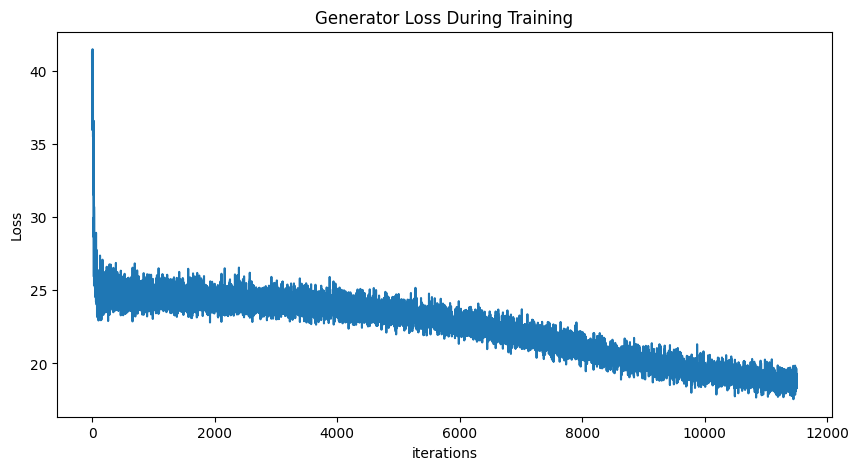

<Figure size 640x480 with 0 Axes>

In [27]:
# generator loss plot
plt.figure(figsize=(10,5))
plt.title("Generator Loss During Training")
plt.plot(G_losses)
plt.xlabel("iterations")
plt.ylabel("Loss")
plt.show()

plt.savefig(os.path.join(output_save_path, 'output_generatorLoss_{}.png'.format(date)))

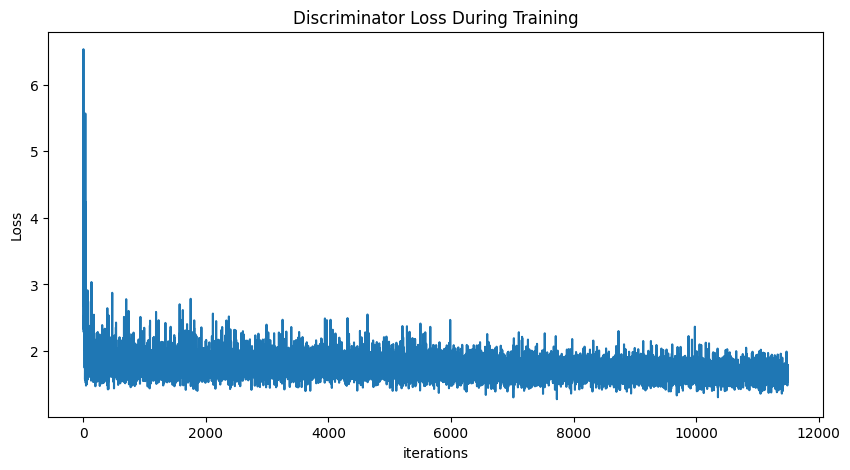

<Figure size 640x480 with 0 Axes>

In [28]:
# discriminator loss plot
plt.figure(figsize=(10,5))
plt.title("Discriminator Loss During Training")
plt.plot(D_losses)
plt.xlabel("iterations")
plt.ylabel("Loss")
plt.show()

plt.savefig(os.path.join(output_save_path, 'output_discriminatorLoss_{}.png'.format(date)))

## Visualize output

In [29]:
# Get all file names from the "generated_images" directory
file_names = os.listdir(output_save_path)
file_names = [name for name in file_names if name.startswith('output_{}_'.format(date))]

# Sort the file names numerically
file_names = sorted(file_names, key=lambda name: int(name.split('_')[3].split('.')[0]))

# Create a list to store the read images
images = []

for file_name in file_names:
    images.append(imageio.imread(os.path.join(output_save_path,file_name)))

imageio.mimsave(os.path.join(output_save_path, 'output_gif_{}.gif'.format(date)), images, fps=1)

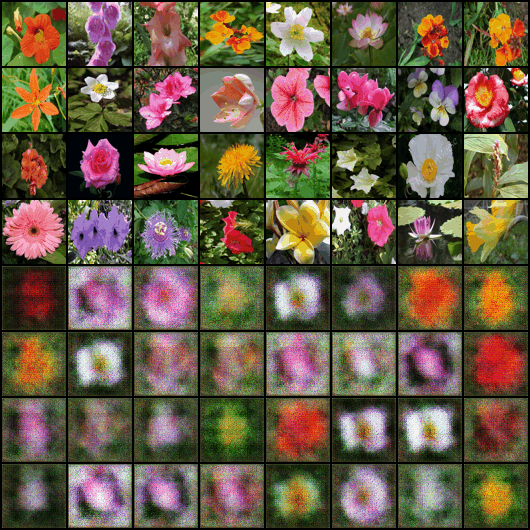

In [30]:
from IPython.display import Image

# Load the GIF
with open(os.path.join(output_save_path, 'output_gif_{}.gif'.format(date)),'rb') as file:
    display(Image(file.read()))

# 텍스트로 이미지 만들기 - 사전학습 모델 활용

## 개요
이번 수업에서는 이미 훈련된 AI 모델을 사용해서 텍스트 설명만으로 이미지를 생성하는 방법을 배워보겠습니다.

### 실생활 활용 예시
- 온라인 쇼핑몰의 상품 이미지 자동 생성
- 소설이나 영화의 컨셉아트 제작
- 교육용 시각 자료 생성
- 게임이나 앱의 캐릭터 디자인
- 마케팅용 창작 이미지 제작

### 학습 목표
1. 사전학습된 Text-to-Image 모델의 원리 이해하기
2. Hugging Face를 통해 최신 AI 모델 사용해보기
3. 다양한 텍스트 프롬프트로 이미지 생성 실습
4. 생성된 이미지의 품질 개선 방법 배우기


## 1. 사전학습 모델이란?

### 사전학습 모델의 개념
사전학습 모델은 대규모 데이터셋으로 미리 훈련된 AI 모델입니다. 마치 이미 공부를 많이 한 학생처럼, 다양한 이미지와 텍스트의 관계를 이미 학습한 상태입니다.

### 왜 사전학습 모델을 사용할까요?
1. **시간 절약**: 처음부터 모델을 훈련하려면 몇 주에서 몇 개월이 걸리지만, 사전학습 모델은 바로 사용 가능합니다
2. **비용 절약**: 대규모 GPU 클러스터 없이도 최신 AI 기술을 사용할 수 있습니다
3. **높은 품질**: 수백만 장의 이미지로 훈련되어 고품질의 결과를 제공합니다
4. **쉬운 접근**: 복잡한 AI 이론을 몰라도 간단한 코드로 사용 가능합니다

### 우리가 사용할 모델: Stable Diffusion
Stable Diffusion은 현재 가장 인기 있는 Text-to-Image 모델 중 하나입니다.
- 무료로 사용 가능
- 높은 품질의 이미지 생성
- 다양한 스타일과 주제 지원


## 2. 환경 설정하기

먼저 필요한 라이브러리들을 설치하고 불러오겠습니다.


In [ ]:
# 필요한 라이브러리 설치 (처음 한 번만 실행)
# 이 셀은 시간이 조금 걸릴 수 있습니다
# %pip install diffusers==0.35.1 transformers==4.56.2 huggingface_hub==0.34.6
# %pip install accelerate==1.10.1 torch==2.8.0 torchvision==0.23.0 koreanize-matplotlib
# %pip install xformers==0.0.32.post2  # 메모리 최적화를 위한 라이브러리

# print("라이브러리 설치가 완료되었습니다!")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 16.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 31.8 MB/s  0:00:00eta 0:00:01
  Attempting uninstall: transformers━━━━━━━━━━━━ 0/2 [diffusers]
    Found existing installation: transformers 4.56.22m0/2 [diffusers]
    Uninstalling transformers-4.56.2:╺━━━━━━━━━━━━━━━━━━━ 1/2 [transformers]
      Successfully uninstalled transformers-4.56.2━━━━━━━━━━━━ 1/2 [transformers]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [transformers] [transformers]
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
ERROR: Could not find a version that satisfies the requirement xformers==0.0.32 (from versions: 0.0.1, 0.0.2, 0.0.3, 0.0.4, 0.0.5, 0.0.6, 0.0.7, 0.0.8, 0.0.9, 0.0.10, 0.0.11, 0.0.12, 0.0.13, 0.0.16rc424, 0.0.16rc425, 0.0.16, 0.0.20, 0.0.21, 0.0.22, 0.0.22.post7, 0.0.23, 0.0.23.post1, 0.0.24, 0.0.25, 0.0.25.post1, 0.0.26.p

In [32]:
# 필요한 라이브러리들을 불러옵니다
import torch
from diffusers import StableDiffusionPipeline
import matplotlib.pyplot as plt
import koreanize_matplotlib

import numpy as np
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

# GPU 사용 가능한지 확인
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"사용 중인 디바이스: {device}")

if device == "cpu":
    print("CPU를 사용합니다. 이미지 생성에 시간이 더 걸릴 수 있습니다.")
else:
    print("GPU를 사용합니다. 빠른 이미지 생성이 가능합니다!")


사용 중인 디바이스: cuda
GPU를 사용합니다. 빠른 이미지 생성이 가능합니다!


## 3. Stable Diffusion
- Stable Diffusion은 오픈소스 이미지 생성 모델로, 텍스트(프롬프트)를 입력하면 그에 맞는 이미지를 생성해주는 확산 기반( diffusion-based ) 딥러닝 모델입니다.

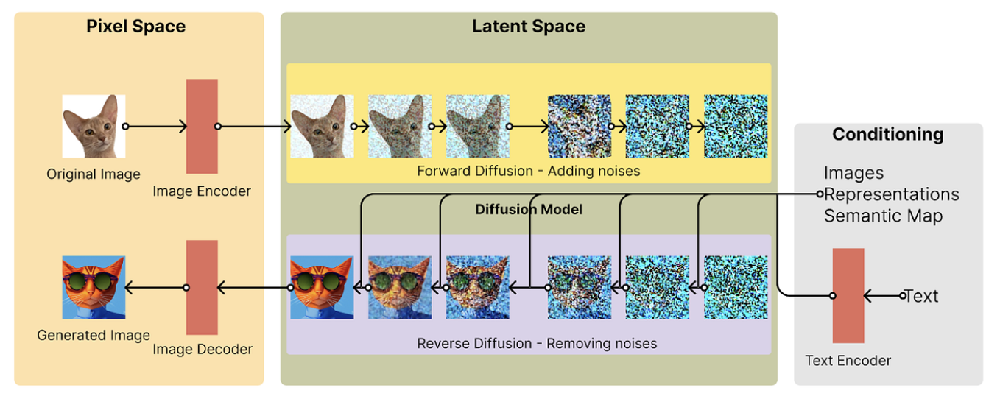

### 핵심 개념
- Diffusion Model (확산 모델)
  - 원래 이미지를 "노이즈(잡음)"로 점점 오염시킨 다음,
그 반대로 노이즈에서 점차 이미지를 복원하는 과정을 학습한 모델이에요.
  - 학습 후에는 랜덤 노이즈 → 점점 정제 → 원하는 이미지 과정을 통해 그림을 만듭니다.

- 텍스트-투-이미지(Text-to-Image)
  - 단순히 "강아지가 초원에서 뛰는 그림" 같은 문장을 입력하면,
이를 **텍스트 인코더(예: CLIP)**가 이해하고, 해당 의미를 반영한 이미지를 만들어냅니다.

- Latent Diffusion (잠재 확산 모델)
  - Stable Diffusion은 이미지를 픽셀 공간에서 직접 다루지 않고,
  - **잠재 공간(latent space)**이라는 압축된 표현에서 작업합니다.
  - 덕분에 계산 효율이 높고, 일반 PC에서도 실행 가능해졌습니다.

### Stable Diffusion 모델 불러오기

이제 사전학습된 Stable Diffusion 모델을 불러오겠습니다.
처음 실행할 때는 모델을 다운로드하므로 시간이 걸릴 수 있습니다.


In [33]:
# Stable Diffusion 모델 불러오기
# 이 과정은 처음에 몇 분 정도 걸릴 수 있습니다

print("Stable Diffusion 모델을 불러오는 중...")
print("처음 실행 시 모델 다운로드로 인해 시간이 걸릴 수 있습니다.")

# 모델 ID 설정 (Hugging Face에서 제공하는 공식 모델)
model_id = "runwayml/stable-diffusion-v1-5"

# 모델 불러오기
pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    dtype=torch.float16 if device == "cuda" else torch.float32,
    use_safetensors=True
)

# GPU 또는 CPU로 모델 이동
pipe = pipe.to(device)

# 메모리 최적화 (GPU 사용 시)
if device == "cuda":
    pipe.enable_model_cpu_offload()
    try:
        pipe.enable_xformers_memory_efficient_attention()
    except:
        print("xformers 최적화를 건너뜁니다.")

print("모델이 성공적으로 로드되었습니다!")
print(f"모델명: {model_id}")
print(f"사용 디바이스: {device}")


Stable Diffusion 모델을 불러오는 중...
처음 실행 시 모델 다운로드로 인해 시간이 걸릴 수 있습니다.


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

merges.txt: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

... (10 outputs left out)

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

Keyword arguments {'dtype': torch.float16} are not expected by StableDiffusionPipeline and will be ignored.


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

xformers 최적화를 건너뜁니다.
모델이 성공적으로 로드되었습니다!
모델명: runwayml/stable-diffusion-v1-5
사용 디바이스: cuda


## 4. 첫 번째 이미지 생성해보기

이제 간단한 텍스트로 첫 번째 이미지를 만들어보겠습니다!


이미지 생성 중... 프롬프트: 'a cute orange cat sitting in a sunny garden'


  0%|          | 0/20 [00:00<?, ?it/s]

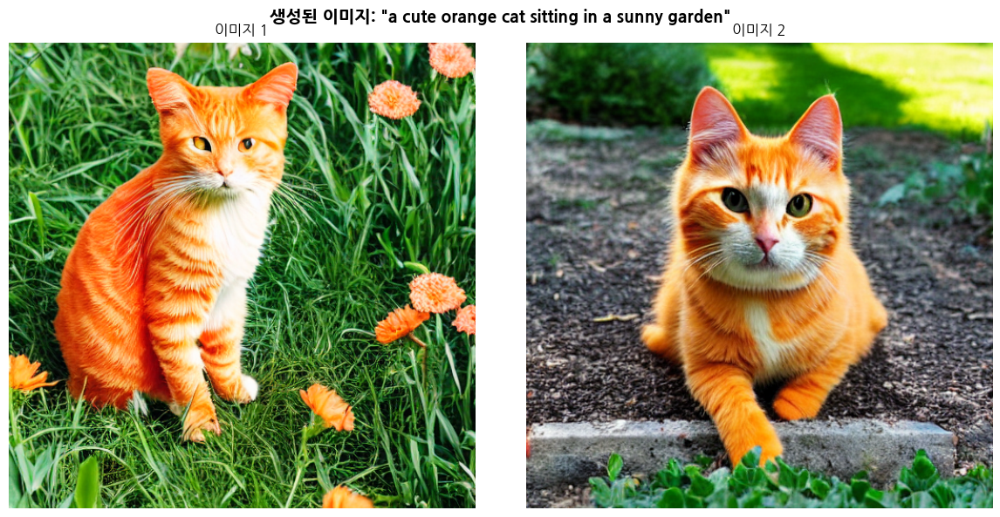

첫 번째 이미지 생성 완료!


In [34]:
# 간단한 텍스트로 이미지 생성하기
def generate_image(prompt, num_images=1, width=512, height=512, steps=20):
    """
    텍스트 프롬프트로 이미지를 생성하는 함수

    Parameters:
    - prompt: 이미지를 설명하는 텍스트
    - num_images: 생성할 이미지 개수
    - width, height: 이미지 크기
    - steps: 생성 단계 수 (높을수록 품질 좋아지지만 시간 오래 걸림)
    """
    print(f"이미지 생성 중... 프롬프트: '{prompt}'")

    # 이미지 생성
    images = pipe(
        prompt,
        num_images_per_prompt=num_images,
        width=width,
        height=height,
        num_inference_steps=steps,
        guidance_scale=7.5  # 텍스트 가이던스 강도
    ).images

    return images

# 첫 번째 예제: 귀여운 고양이
prompt1 = "a cute orange cat sitting in a sunny garden"
images1 = generate_image(prompt1, num_images=2)

# 결과 보여주기
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
fig.suptitle(f'생성된 이미지: "{prompt1}"', fontsize=14, fontweight='bold')

for i, img in enumerate(images1):
    axes[i].imshow(img)
    axes[i].axis('off')
    axes[i].set_title(f'이미지 {i+1}', fontsize=12)

plt.tight_layout()
plt.show()

print("첫 번째 이미지 생성 완료!")


## 5. 다양한 스타일의 이미지 생성하기

이제 다양한 스타일과 주제로 이미지를 생성해보겠습니다.
프롬프트(텍스트 설명)를 어떻게 작성하느냐에 따라 결과가 크게 달라집니다.


생성 중 (1/4): a beautiful sunset over mountains, digital art
이미지 생성 중... 프롬프트: 'a beautiful sunset over mountains, digital art'


  0%|          | 0/20 [00:00<?, ?it/s]

생성 중 (2/4): a futuristic city with flying cars, cyberpunk style
이미지 생성 중... 프롬프트: 'a futuristic city with flying cars, cyberpunk style'


  0%|          | 0/20 [00:00<?, ?it/s]

생성 중 (3/4): a magical forest with glowing mushrooms, fantasy art
이미지 생성 중... 프롬프트: 'a magical forest with glowing mushrooms, fantasy art'


  0%|          | 0/20 [00:00<?, ?it/s]

생성 중 (4/4): a vintage car on a country road, oil painting style
이미지 생성 중... 프롬프트: 'a vintage car on a country road, oil painting style'


  0%|          | 0/20 [00:00<?, ?it/s]

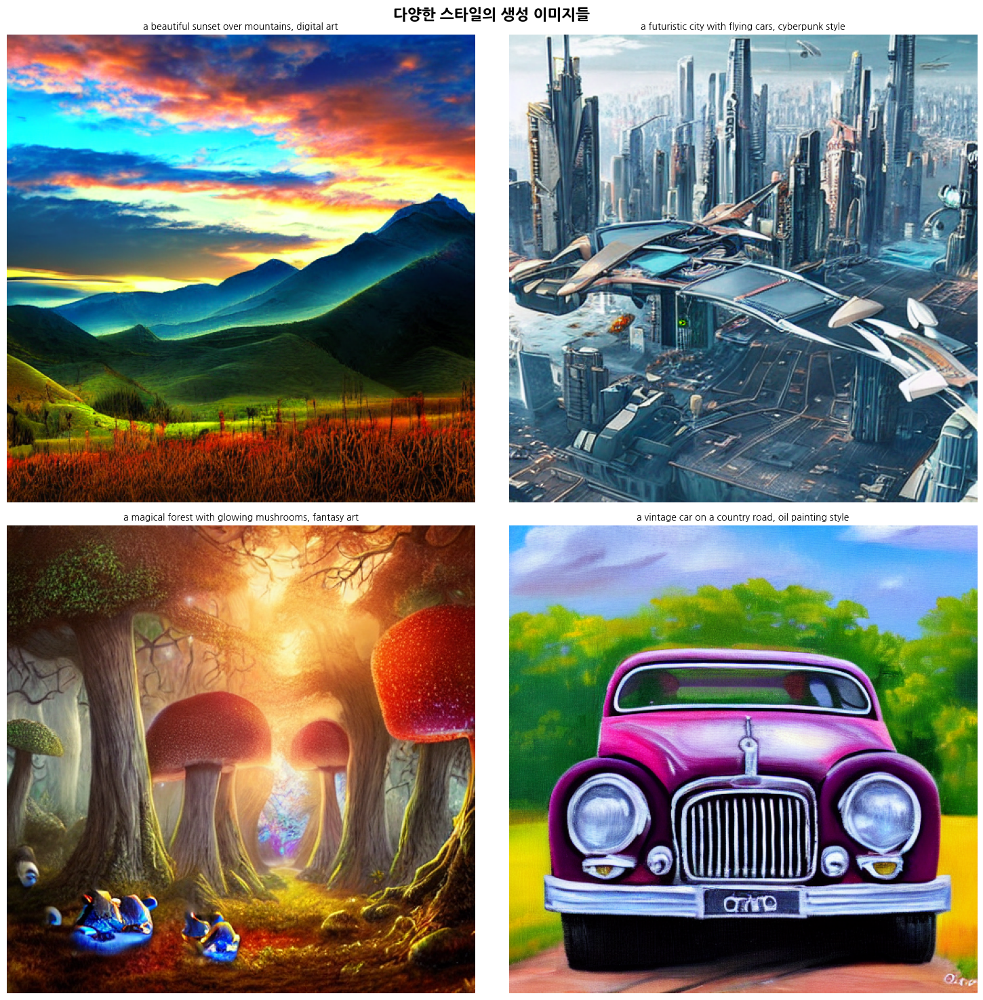

모든 이미지 생성 완료!


In [35]:
# 다양한 스타일의 프롬프트들
prompts = [
    "a beautiful sunset over mountains, digital art",
    "a futuristic city with flying cars, cyberpunk style",
    "a magical forest with glowing mushrooms, fantasy art",
    "a vintage car on a country road, oil painting style"
]

# 각 프롬프트로 이미지 생성
fig, axes = plt.subplots(2, 2, figsize=(15, 15))
fig.suptitle('다양한 스타일의 생성 이미지들', fontsize=16, fontweight='bold')

for i, prompt in enumerate(prompts):
    print(f"생성 중 ({i+1}/4): {prompt}")

    # 이미지 생성
    image = generate_image(prompt, num_images=1)[0]

    # 결과 표시
    row = i // 2
    col = i % 2

    axes[row, col].imshow(image)
    axes[row, col].axis('off')
    axes[row, col].set_title(prompt, fontsize=10, wrap=True)

plt.tight_layout()
plt.show()

print("모든 이미지 생성 완료!")


## 6. 프롬프트 작성 팁

좋은 이미지를 생성하려면 프롬프트를 잘 작성하는 것이 중요합니다.
다음은 효과적인 프롬프트 작성 방법들입니다.

### 프롬프트 작성 가이드

#### 1. 구체적으로 설명하기
- 나쁜 예: "dog"
- 좋은 예: "a golden retriever puppy playing in a green meadow"

#### 2. 스타일 키워드 추가하기
- 디지털 아트: "digital art", "concept art"
- 사진 스타일: "photography", "photorealistic"
- 그림 스타일: "oil painting", "watercolor", "pencil sketch"
- 애니메이션: "anime style", "cartoon"

#### 3. 품질 향상 키워드
- "high quality", "detailed", "4k", "masterpiece"
- "professional", "award winning"

#### 4. 조명과 색상 지정
- "soft lighting", "dramatic lighting", "golden hour"
- "vibrant colors", "pastel colors", "monochrome"

#### 5. 카메라 앵글 (사진의 경우)
- "close-up", "wide shot", "bird's eye view"
- "portrait", "landscape orientation"


기본 프롬프트와 상세 프롬프트 비교
기본: a house
상세: a cozy wooden cottage in a snowy mountain landscape, warm lights glowing from windows, digital art, high quality, detailed

이미지 생성 중... 프롬프트: 'a house'


  0%|          | 0/20 [00:00<?, ?it/s]

이미지 생성 중... 프롬프트: 'a cozy wooden cottage in a snowy mountain landscape, warm lights glowing from windows, digital art, high quality, detailed'


  0%|          | 0/20 [00:00<?, ?it/s]

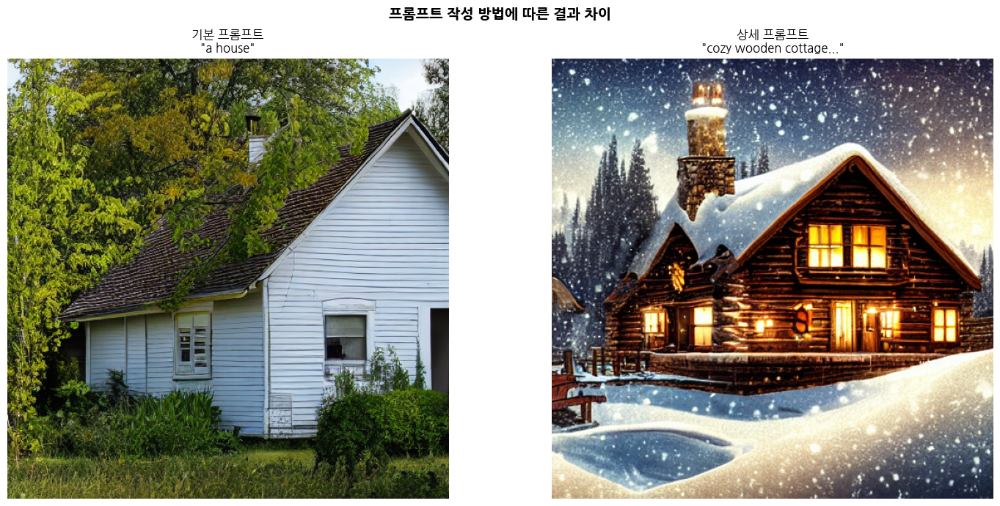

상세한 프롬프트가 더 구체적이고 품질 높은 이미지를 만들어냅니다!


In [36]:
# 프롬프트 개선 예제
# 같은 주제를 다른 방식으로 표현해보기

basic_prompt = "a house"
detailed_prompt = "a cozy wooden cottage in a snowy mountain landscape, warm lights glowing from windows, digital art, high quality, detailed"

print("기본 프롬프트와 상세 프롬프트 비교")
print(f"기본: {basic_prompt}")
print(f"상세: {detailed_prompt}")
print()

# 두 프롬프트로 이미지 생성
basic_image = generate_image(basic_prompt)[0]
detailed_image = generate_image(detailed_prompt)[0]

# 결과 비교
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
fig.suptitle('프롬프트 작성 방법에 따른 결과 차이', fontsize=14, fontweight='bold')

axes[0].imshow(basic_image)
axes[0].set_title('기본 프롬프트\n"a house"', fontsize=12)
axes[0].axis('off')

axes[1].imshow(detailed_image)
axes[1].set_title('상세 프롬프트\n"cozy wooden cottage..."', fontsize=12)
axes[1].axis('off')

plt.tight_layout()
plt.show()

print("상세한 프롬프트가 더 구체적이고 품질 높은 이미지를 만들어냅니다!")


## 7. 실습: 다양한 주제로 이미지 생성하기

이제 여러분이 직접 다양한 주제로 이미지를 생성해보세요!
아래 예제들을 참고하거나 자신만의 프롬프트를 만들어보세요.


선택된 프롬프트: a peaceful lake surrounded by autumn trees, reflection in water, golden hour lighting
이미지 생성 중... 프롬프트: 'a peaceful lake surrounded by autumn trees, reflection in water, golden hour lighting'


  0%|          | 0/20 [00:00<?, ?it/s]

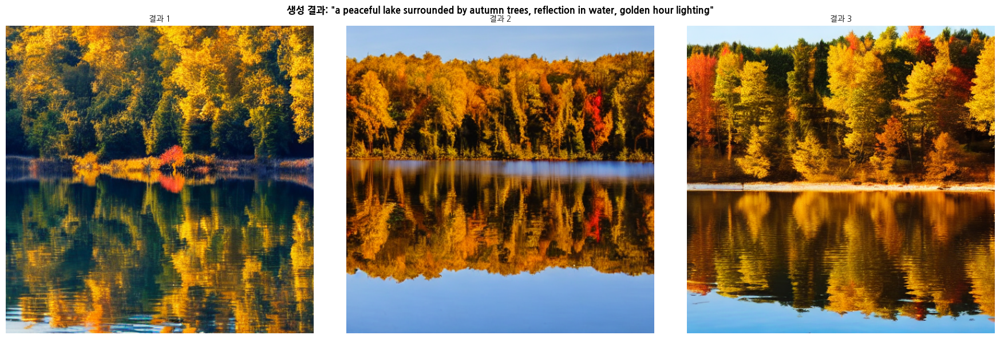


다른 프롬프트를 시도하려면 'selected_prompt_index' 값을 바꾸고 다시 실행해보세요!


In [37]:
# 실습용 프롬프트 예제들
practice_prompts = [
    # 자연
    "a peaceful lake surrounded by autumn trees, reflection in water, golden hour lighting",

    # 음식
    "a delicious chocolate cake with strawberries, professional food photography, studio lighting",

    # 동물
    "a majestic eagle soaring over snow-capped mountains, wildlife photography, detailed",

    # 과학 판타지
    "a space station orbiting a distant planet, sci-fi concept art, detailed, futuristic",

    # 일상
    "a cozy coffee shop interior with warm lighting, people reading books, atmospheric"
]

# 원하는 프롬프트 선택 (0-4 중 선택)
selected_prompt_index = 0  # 이 숫자를 바꿔서 다른 프롬프트 시도해보세요!

if 0 <= selected_prompt_index < len(practice_prompts):
    selected_prompt = practice_prompts[selected_prompt_index]
    print(f"선택된 프롬프트: {selected_prompt}")

    # 이미지 생성 (여러 장 생성해서 비교)
    practice_images = generate_image(selected_prompt, num_images=3)

    # 결과 표시
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle(f'생성 결과: "{selected_prompt}"', fontsize=12, fontweight='bold')

    for i, img in enumerate(practice_images):
        axes[i].imshow(img)
        axes[i].axis('off')
        axes[i].set_title(f'결과 {i+1}', fontsize=10)

    plt.tight_layout()
    plt.show()

else:
    print("잘못된 인덱스입니다. 0-4 사이의 숫자를 선택해주세요.")

print("\n다른 프롬프트를 시도하려면 'selected_prompt_index' 값을 바꾸고 다시 실행해보세요!")


## 8. 나만의 프롬프트로 이미지 생성하기

이제 여러분만의 창의적인 프롬프트를 작성해서 이미지를 생성해보세요!


나만의 프롬프트: a magical library with floating books and glowing crystals, fantasy art, detailed, mysterious atmosphere
이미지 생성 중...
이미지 생성 중... 프롬프트: 'a magical library with floating books and glowing crystals, fantasy art, detailed, mysterious atmosphere'


  0%|          | 0/30 [00:00<?, ?it/s]

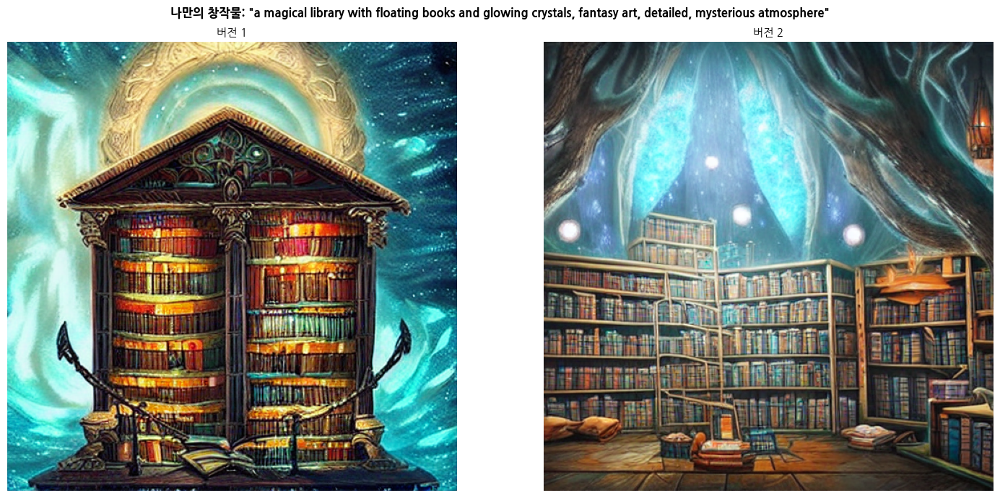


프롬프트를 수정해서 다양한 이미지를 만들어보세요!
팁: 스타일, 색상, 조명, 분위기 등의 키워드를 추가하면 더 원하는 결과를 얻을 수 있습니다.


In [38]:
# 여기에 여러분만의 프롬프트를 작성해보세요!
my_prompt = "a magical library with floating books and glowing crystals, fantasy art, detailed, mysterious atmosphere"

print(f"나만의 프롬프트: {my_prompt}")
print("이미지 생성 중...")

# 이미지 생성
my_images = generate_image(my_prompt, num_images=2, steps=30)  # 더 높은 품질을 위해 steps 증가

# 결과 표시
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
fig.suptitle(f'나만의 창작물: "{my_prompt}"', fontsize=12, fontweight='bold')

for i, img in enumerate(my_images):
    axes[i].imshow(img)
    axes[i].axis('off')
    axes[i].set_title(f'버전 {i+1}', fontsize=11)

plt.tight_layout()
plt.show()

print("\n프롬프트를 수정해서 다양한 이미지를 만들어보세요!")
print("팁: 스타일, 색상, 조명, 분위기 등의 키워드를 추가하면 더 원하는 결과를 얻을 수 있습니다.")


## 9. 이미지 저장하기

생성한 이미지를 컴퓨터에 저장하는 방법을 배워보겠습니다.


In [39]:
# 이미지 저장 함수
def save_images(images, prompts, folder_name="generated_images"):
    """
    생성된 이미지들을 파일로 저장하는 함수
    """
    import os
    from datetime import datetime

    # 저장 폴더 생성
    if not os.path.exists(folder_name):
        os.makedirs(folder_name)

    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

    saved_files = []

    for i, (image, prompt) in enumerate(zip(images, prompts)):
        # 파일명 생성 (특수문자 제거)
        safe_prompt = "".join(c for c in prompt if c.isalnum() or c in (' ', '-', '_')).rstrip()[:50]
        filename = f"{timestamp}_{i+1}_{safe_prompt}.png"
        filepath = os.path.join(folder_name, filename)

        # 이미지 저장
        image.save(filepath)
        saved_files.append(filepath)
        print(f"저장됨: {filepath}")

    return saved_files

# 예제: 여러 이미지 생성하고 저장하기
save_prompts = [
    "a serene japanese garden with cherry blossoms",
    "a steampunk airship flying through clouds"
]

images_to_save = []
for prompt in save_prompts:
    print(f"생성 중: {prompt}")
    img = generate_image(prompt, num_images=1)[0]
    images_to_save.append(img)

# 이미지 저장
print("\n이미지 저장 중...")
saved_files = save_images(images_to_save, save_prompts)

print(f"\n총 {len(saved_files)}개의 이미지가 저장되었습니다!")
print("저장된 폴더: generated_images/")


생성 중: a serene japanese garden with cherry blossoms
이미지 생성 중... 프롬프트: 'a serene japanese garden with cherry blossoms'


  0%|          | 0/20 [00:00<?, ?it/s]

생성 중: a steampunk airship flying through clouds
이미지 생성 중... 프롬프트: 'a steampunk airship flying through clouds'


  0%|          | 0/20 [00:00<?, ?it/s]


이미지 저장 중...
저장됨: generated_images/20260506_093433_1_a serene japanese garden with cherry blossoms.png
저장됨: generated_images/20260506_093433_2_a steampunk airship flying through clouds.png

총 2개의 이미지가 저장되었습니다!
저장된 폴더: generated_images/


## 10. 고급 기능: 이미지 품질 개선하기

생성된 이미지의 품질을 높이는 다양한 방법들을 알아보겠습니다.


1. 네거티브 프롬프트 없이 생성...
이미지 생성 중... 프롬프트: 'a beautiful portrait of a woman, professional photography, high quality, detailed, elegant'


  0%|          | 0/30 [00:00<?, ?it/s]


2. 네거티브 프롬프트와 함께 생성...
고품질 이미지 생성 중...
프롬프트: a beautiful portrait of a woman, professional photography, high quality, detailed, elegant
네거티브 프롬프트: blurry, low quality, distorted, ugly, bad anatomy, extra limbs


  0%|          | 0/30 [00:00<?, ?it/s]

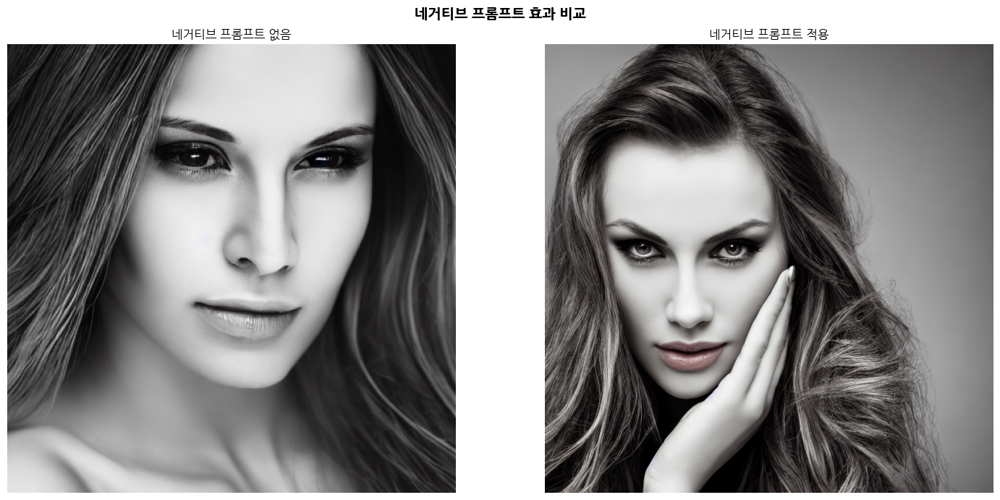

네거티브 프롬프트를 사용하면 원하지 않는 요소들을 제거할 수 있습니다!


In [40]:
# 고급 이미지 생성 함수
def generate_high_quality_image(prompt, negative_prompt="", steps=50, guidance_scale=7.5, width=768, height=768):
    """
    고품질 이미지 생성 함수

    Parameters:
    - prompt: 원하는 이미지 설명
    - negative_prompt: 원하지 않는 요소들 (예: "blurry, low quality")
    - steps: 생성 단계 수 (높을수록 품질 좋음, 시간 오래 걸림)
    - guidance_scale: 텍스트 가이던스 강도 (7-15 권장)
    """

    print(f"고품질 이미지 생성 중...")
    print(f"프롬프트: {prompt}")
    if negative_prompt:
        print(f"네거티브 프롬프트: {negative_prompt}")

    result = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        num_inference_steps=steps,
        guidance_scale=guidance_scale,
        width=width,
        height=height,
        num_images_per_prompt=1
    )

    return result.images[0]

# 예제: 네거티브 프롬프트 사용하기
positive_prompt = "a beautiful portrait of a woman, professional photography, high quality, detailed, elegant"
negative_prompt = "blurry, low quality, distorted, ugly, bad anatomy, extra limbs"

# 네거티브 프롬프트 없이 생성
print("1. 네거티브 프롬프트 없이 생성...")
image_without_negative = generate_image(positive_prompt, steps=30)[0]

# 네거티브 프롬프트와 함께 생성
print("\n2. 네거티브 프롬프트와 함께 생성...")
image_with_negative = generate_high_quality_image(positive_prompt, negative_prompt, steps=30)

# 결과 비교
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
fig.suptitle('네거티브 프롬프트 효과 비교', fontsize=14, fontweight='bold')

axes[0].imshow(image_without_negative)
axes[0].set_title('네거티브 프롬프트 없음', fontsize=12)
axes[0].axis('off')

axes[1].imshow(image_with_negative)
axes[1].set_title('네거티브 프롬프트 적용', fontsize=12)
axes[1].axis('off')

plt.tight_layout()
plt.show()

print("네거티브 프롬프트를 사용하면 원하지 않는 요소들을 제거할 수 있습니다!")


## 11. 최종 프로젝트: 나만의 아트 갤러리 만들기

배운 내용을 종합해서 다양한 주제의 이미지들로 나만의 아트 갤러리를 만들어보겠습니다.


In [41]:
# 나만의 아트 갤러리 프로젝트
gallery_themes = {
    "자연의 아름다움": [
        "a majestic waterfall in a tropical rainforest, mist and rainbow, detailed nature photography",
        "northern lights dancing over a snowy landscape, aurora borealis, magical atmosphere"
    ],
    "미래 도시": [
        "a cyberpunk cityscape at night, neon lights, flying cars, futuristic architecture",
        "a sustainable eco-city with vertical gardens, clean energy, harmony with nature"
    ],
    "환상적인 세계": [
        "a floating island in the sky with waterfalls, fantasy landscape, magical clouds",
        "an underwater palace with mermaids, coral gardens, bioluminescent sea creatures"
    ]
}

print("나만의 아트 갤러리 생성 중...")
print("이 과정은 몇 분 정도 걸릴 수 있습니다.\n")

gallery_images = {}
negative_prompt = "blurry, low quality, distorted, ugly, bad composition"

for theme, prompts in gallery_themes.items():
    print(f"테마: {theme}")
    theme_images = []

    for i, prompt in enumerate(prompts):
        print(f"  생성 중 {i+1}/{len(prompts)}: {prompt[:50]}...")
        img = generate_high_quality_image(prompt, negative_prompt, steps=40, width=768, height=768)
        theme_images.append(img)

    gallery_images[theme] = theme_images
    print(f"  {theme} 완성!\n")

print("갤러리 생성 완료! 결과를 확인해보세요:")


나만의 아트 갤러리 생성 중...
이 과정은 몇 분 정도 걸릴 수 있습니다.

테마: 자연의 아름다움
  생성 중 1/2: a majestic waterfall in a tropical rainforest, mis...
고품질 이미지 생성 중...
프롬프트: a majestic waterfall in a tropical rainforest, mist and rainbow, detailed nature photography
네거티브 프롬프트: blurry, low quality, distorted, ugly, bad composition


  0%|          | 0/40 [00:00<?, ?it/s]

  생성 중 2/2: northern lights dancing over a snowy landscape, au...
고품질 이미지 생성 중...
프롬프트: northern lights dancing over a snowy landscape, aurora borealis, magical atmosphere
네거티브 프롬프트: blurry, low quality, distorted, ugly, bad composition


  0%|          | 0/40 [00:00<?, ?it/s]

  자연의 아름다움 완성!

테마: 미래 도시
  생성 중 1/2: a cyberpunk cityscape at night, neon lights, flyin...
고품질 이미지 생성 중...
프롬프트: a cyberpunk cityscape at night, neon lights, flying cars, futuristic architecture
네거티브 프롬프트: blurry, low quality, distorted, ugly, bad composition


  0%|          | 0/40 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/40 [00:00<?, ?it/s]

  생성 중 2/2: an underwater palace with mermaids, coral gardens,...
고품질 이미지 생성 중...
프롬프트: an underwater palace with mermaids, coral gardens, bioluminescent sea creatures
네거티브 프롬프트: blurry, low quality, distorted, ugly, bad composition


  0%|          | 0/40 [00:00<?, ?it/s]

  환상적인 세계 완성!

갤러리 생성 완료! 결과를 확인해보세요:


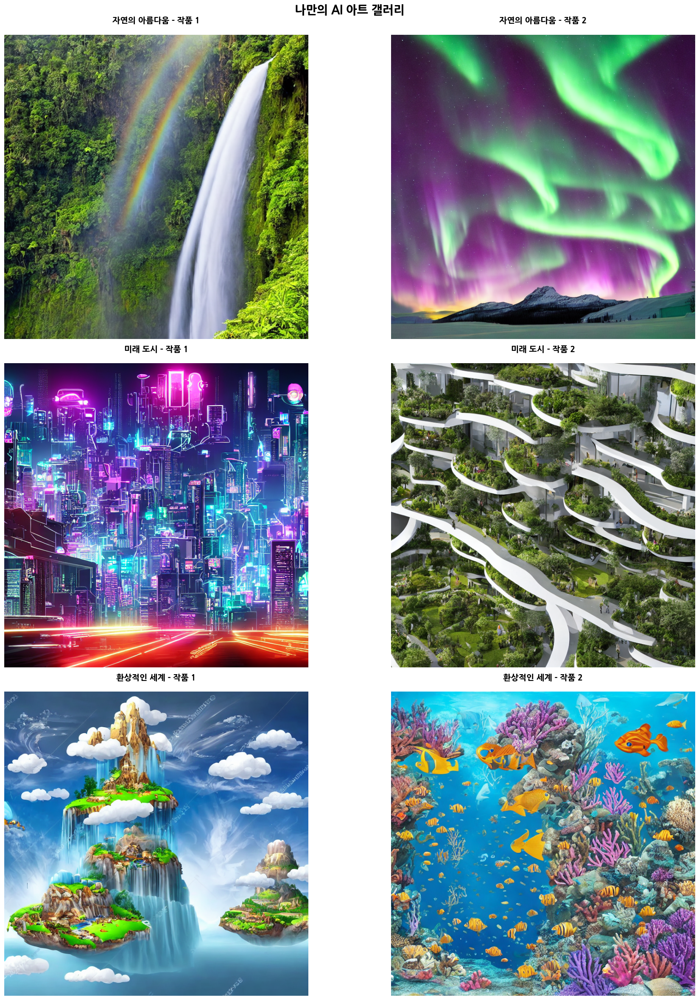

축하합니다! 나만의 AI 아트 갤러리가 완성되었습니다!
각 작품은 여러분이 작성한 텍스트 프롬프트를 바탕으로 AI가 창작한 독특한 예술작품입니다.


In [42]:
# 갤러리 전시하기
fig, axes = plt.subplots(3, 2, figsize=(20, 24))
fig.suptitle('나만의 AI 아트 갤러리', fontsize=20, fontweight='bold', y=0.98)

row = 0
for theme, images in gallery_images.items():
    for col, img in enumerate(images):
        axes[row, col].imshow(img)
        axes[row, col].axis('off')
        axes[row, col].set_title(f'{theme} - 작품 {col+1}', fontsize=14, fontweight='bold', pad=20)
    row += 1

plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.show()

print("축하합니다! 나만의 AI 아트 갤러리가 완성되었습니다!")
print("각 작품은 여러분이 작성한 텍스트 프롬프트를 바탕으로 AI가 창작한 독특한 예술작품입니다.")
